Các điểm bao lồi là:
(-4, 2)
(-3, -2)
(-1, -4)
(1, -4)
(3, -4)
(5, -2)
(-1, 4)
Diện tích bao lồi: 43.00


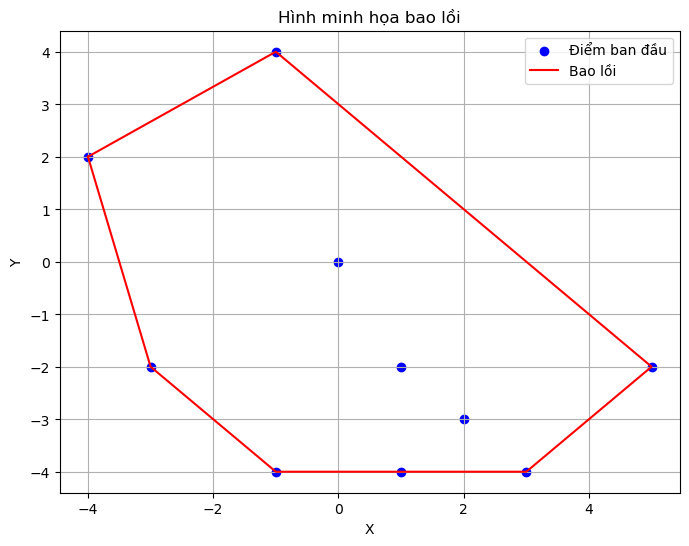

In [1]:
import matplotlib.pyplot as plt

# Định nghĩa lớp Point
class Point:
    def __init__(self, x, y):
        self.x = x
        self.y = y

# Hàm tìm hướng của bộ ba điểm (p, q, r)
# 0 -> p, q, và r thẳng hàng
# 1 -> Theo chiều kim đồng hồ
# 2 -> Ngược chiều kim đồng hồ
def orientation(p, q, r):
    val = (q.y - p.y) * (r.x - q.x) - (q.x - p.x) * (r.y - q.y)
    if val == 0:
        return 0
    return 1 if val > 0 else 2

# Hàm tính diện tích bao lồi bằng công thức Shoelace
def calculate_area(hull):
    area = 0.0
    n = len(hull)
    for i in range(n):
        j = (i + 1) % n
        area += (hull[i].x * hull[j].y) - (hull[i].y * hull[j].x)
    return abs(area) / 2.0

# Hàm tìm bao lồi
def convex_hull(points):
    n = len(points)
    if n < 3:
        print("Không thể tạo bao lồi.")
        return []

    hull = []

    # Tìm điểm bên trái nhất
    leftmost = min(range(n), key=lambda i: points[i].x)
    p = leftmost

    while True:
        hull.append(points[p])
        q = (p + 1) % n

        for i in range(n):
            if orientation(points[p], points[i], points[q]) == 2:
                q = i
        
        p = q
        if p == leftmost:
            break

    return hull

# Hàm vẽ các điểm và bao lồi
def plot(points, hull):
    # Các điểm gốc
    x_points = [p.x for p in points]
    y_points = [p.y for p in points]
    
    # Các điểm của bao lồi
    x_hull = [p.x for p in hull] + [hull[0].x]  # Đóng kín đường
    y_hull = [p.y for p in hull] + [hull[0].y]

    plt.figure(figsize=(8, 6))
    plt.scatter(x_points, y_points, color='blue', label='Điểm ban đầu')
    plt.plot(x_hull, y_hull, color='red', label='Bao lồi')
    plt.title('Hình minh họa bao lồi')
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.legend()
    plt.grid()
    plt.show()

# Hàm chính
def main():
    # Các điểm đã cho
    points = [
        Point(-4, 2), Point(-3, -2), Point(-1, 4),
        Point(-1, -4), Point(0, 0), Point(1, -2),
        Point(1, -4), Point(2, -3), Point(3, -4),
        Point(5, -2)
    ]

    # Tìm bao lồi
    hull = convex_hull(points)

    # In ra các điểm của bao lồi
    print("Các điểm bao lồi là:")
    for p in hull:
        print(f"({p.x}, {p.y})")

    # Tính diện tích của bao lồi
    area = calculate_area(hull)
    print(f"Diện tích bao lồi: {area:.2f}")

    # Vẽ các điểm và bao lồi
    plot(points, hull)

# Chạy hàm chính
if __name__ == "__main__":
    main()
